#### Import the Libraries

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### Importing the data

In [45]:
df = pd.read_csv('/content/Social_Network_Ads .csv')

#### Define X and Y

In [53]:
x=df.iloc[:,:-1].values
y=df.iloc[:,-1].values

#### Train Test Split

In [54]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

#### Feature Scaling

In [55]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test= sc.transform(x_test)

#### Define the model

In [74]:
from sklearn.svm import SVC
classifier=SVC(kernel='linear',random_state=42)

#### Train the model

In [76]:
classifier.fit(x_train,y_train)

SVC(kernel='linear', random_state=42)

In [77]:
print(classifier.predict(sc.transform([[30,42000]])))

[0]


#### Test the model

In [78]:

y_pred = classifier.predict(x_test)
print(np.concatenate((y_pred.reshape(len(y_pred),1),y_test.reshape(len(y_test),1)),1))

[[1 1]
 [0 0]
 [0 0]
 [1 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [1 0]
 [0 0]
 [0 0]
 [1 1]
 [0 1]
 [1 0]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 1]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [1 1]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 0]
 [0 1]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [0 0]]


In [81]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
cm = confusion_matrix(y_test, y_pred)
print(cm)
print("classification_report\n")
classification_report(y_test,y_pred)

[[48  3]
 [11 18]]
classification_report



'              precision    recall  f1-score   support\n\n           0       0.81      0.94      0.87        51\n           1       0.86      0.62      0.72        29\n\n    accuracy                           0.82        80\n   macro avg       0.84      0.78      0.80        80\nweighted avg       0.83      0.82      0.82        80\n'

In [79]:
print("accuracy_score")
accuracy_score(y_test, y_pred)

accuracy_score


0.825

#### Visualising the Training set results

/tmp/ipykernel_1420/3763154570.py:10: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


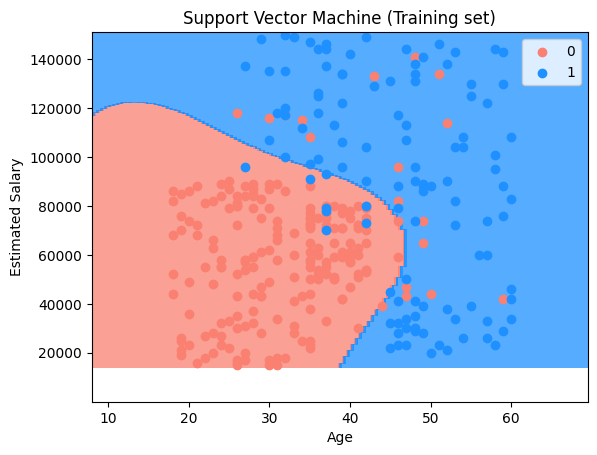

In [66]:
from matplotlib.colors import ListedColormap
x_set, y_set = sc.inverse_transform(x_train), y_train
x1, x2 = np.meshgrid(np.arange(start = x_set[:, 0].min() - 10, stop = x_set[:, 0].max() + 10, step = 0.5),
                     np.arange(start = x_set[:, 1].min() - 1000, stop = x_set[:, 1].max() + 1000, step = 0.5))
plt.contourf(x1, x2, classifier.predict(sc.transform(np.array([x1.ravel(), x2.ravel()]).T)).reshape(x1.shape),
             alpha = 0.75, cmap = ListedColormap(['#FA8072', '#1E90FF']))
plt.xlim(x1.min(), x1.max())
plt.ylim(x1.min(), x2.max())
for i, j in enumerate(np.unique(y_set)):
  plt.scatter(
      x_set[y_set == j, 0],
      x_set[y_set == j, 1],
      c=ListedColormap(["#FA8072", "#1E90FF"])(i),
      label=j,
  )
plt.title('Support Vector Machine (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()